# Колоректальный рак по микробиому кала

Ноутбук проходит восемь этапов задачи. Положите `train.csv` и `test.csv` в папку `DATA_DIR`, затем выполните Run All.

**Биология в трёх фразах**
1. При раке в кале появляются **ротовые бактерии**: Parvimonas, Fusobacterium, Gemella, Peptostreptococcus и другие. У здоровых их почти нет, поэтому решает сам факт присутствия.
2. Бактерий **гниения белка** становится больше, а бактерий, делающих **бутират**, меньше. Это химический сдвиг.
3. Общее разнообразие рак не отличает. Страна и возраст — помехи, а не сигнал.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold

DATA_DIR = '.'
SEED = 0
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
META = ['sample_id', 'label', 'cohort', 'age', 'gender', 'bmi', 'library_size']
TAXA = [c for c in train.columns if c not in META]
y = train['label'].values
cohort = train['cohort'].values
print('train', train.shape, 'test', test.shape, 'таксонов', len(TAXA))

train (415, 856) test (160, 855) таксонов 849


## 1. Разведочный анализ

In [2]:
X = train[TAXA]
print('классы:', train.label.value_counts().to_dict())
print('доля нулей в таблице таксонов:', round((X == 0).mean().mean(), 3))
print('сумма долей в строке (остаток — неназначенные прочтения):', X.sum(1).describe().round(3).to_dict())
prev = (X > 0).mean()
print('таксонов, встречающихся > 10% образцов:', int((prev > 0.10).sum()))

# разнообразие: ожидаем, что рак его НЕ отличает
p = X.div(X.sum(1), axis=0)
shannon = -(p.replace(0, np.nan) * np.log(p.replace(0, np.nan))).sum(1)
print('Шеннон AUC:', round(roc_auc_score(y, shannon), 3), 'p =', round(mannwhitneyu(shannon[y==1], shannon[y==0]).pvalue, 3))

классы: {0: 210, 1: 205}
доля нулей в таблице таксонов: 0.72
сумма долей в строке (остаток — неназначенные прочтения): {'count': 415.0, 'mean': 0.956, 'std': 0.039, 'min': 0.568, '25%': 0.95, '50%': 0.967, '75%': 0.977, 'max': 0.996}
таксонов, встречающихся > 10% образцов: 546
Шеннон AUC: 0.458 p = 0.141


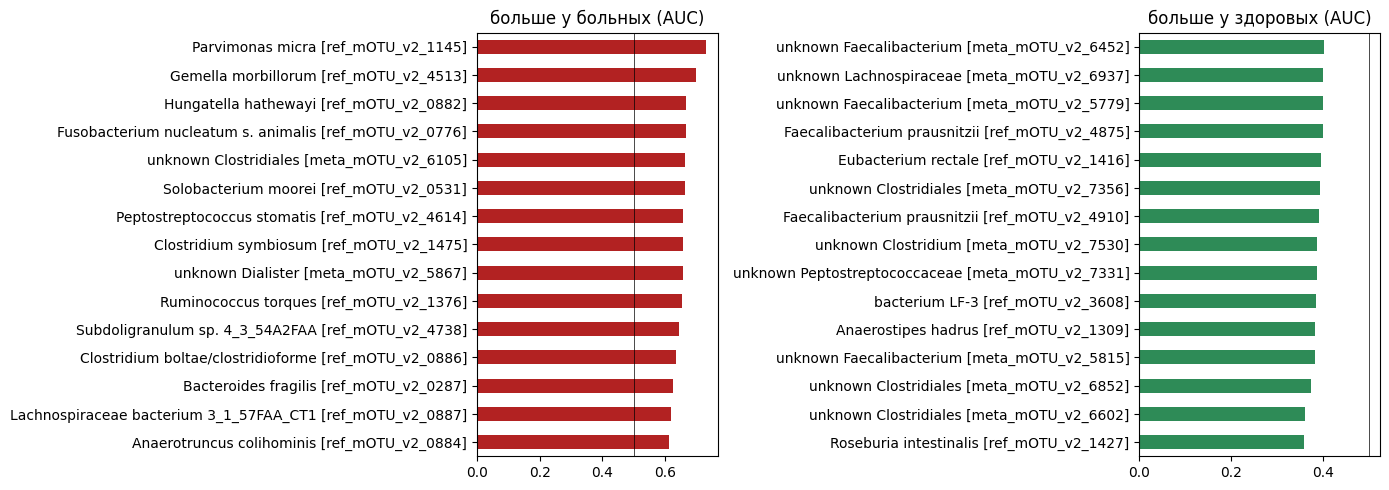

In [3]:
# главные отдельные таксоны: AUC каждого столбца
keep = prev[prev > 0.10].index
lx_all = np.log10(X[keep] + 1e-5)
auc_single = pd.Series({c: roc_auc_score(y, lx_all[c]) for c in keep}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
auc_single.tail(15).plot.barh(ax=ax[0], color='firebrick'); ax[0].set_title('больше у больных (AUC)'); ax[0].axvline(0.5, c='k', lw=.5)
auc_single.head(15).plot.barh(ax=ax[1], color='seagreen'); ax[1].set_title('больше у здоровых (AUC)'); ax[1].axvline(0.5, c='k', lw=.5)
plt.tight_layout(); plt.show()

## 2. Дисбаланс метаданных

Ищем то, что модель может спутать с раком: страну, возраст, пол.

In [4]:
print(pd.crosstab(train.cohort, train.label, margins=True))
print()
print(train.groupby('label')[['age', 'bmi', 'library_size']].median())
for c in ['age', 'bmi', 'library_size']:
    m = train[c].notna()
    print(f'{c}: AUC сам по себе {roc_auc_score(y[m], train.loc[m, c]):.3f}')
print('доля мужчин: больные', round((train.gender[y==1]=='M').mean(), 2), 'здоровые', round((train.gender[y==0]=='M').mean(), 2))

label     0    1  All
cohort               
AUS      48   31   79
CHI      41   58   99
FRA      43   37   80
GER      44   43   87
USA      34   36   70
All     210  205  415

        age    bmi  library_size
label                           
0      63.0  24.45    23808971.0
1      66.0  25.65    26701988.0
age: AUC сам по себе 0.615
bmi: AUC сам по себе 0.536
library_size: AUC сам по себе 0.564
доля мужчин: больные 0.67 здоровые 0.6


**Вывод.** В Китае больных больше, чем здоровых (58 против 41), а в других странах примерно поровну. Возраст сам по себе даёт AUC около 0,62. Поэтому `cohort` в модель не подаём, а используем для стратификации и проверки на новой стране. `age`, `bmi` и `library_size` не берём: они слабые, а возраст подменил бы бактериальный сигнал.

## 3. Разбиение данных

Пять фолдов с двумя повторами, стратифицированных по стране и классу сразу. Отдельно — проверка «новая страна»: обучаемся на четырёх странах, проверяем на пятой.

In [5]:
strata = np.array([f'{c}_{l}' for c, l in zip(cohort, y)])
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
COHORTS = np.unique(cohort)

def evaluate(make_model, F):
    F = np.asarray(F)
    cv = [roc_auc_score(y[te], make_model().fit(F[tr], y[tr]).predict_proba(F[te])[:, 1]) for tr, te in CV.split(F, strata)]
    loco = {k: roc_auc_score(y[cohort == k], make_model().fit(F[cohort != k], y[cohort != k]).predict_proba(F[cohort == k])[:, 1]) for k in COHORTS}
    return np.mean(cv), np.std(cv), np.mean(list(loco.values())), loco

## 4. Предобработка

* Оставляем таксоны, встречающиеся больше чем в 10% образцов train. Фильтр не смотрит на метку, поэтому утечки нет.
* Переводим доли в `log10(x + 1e-5)`: они различаются на порядки.
* Несколько mOTU одного вида (например, четыре у Faecalibacterium prausnitzii) **не складываем**: они ведут себя по-разному.

In [6]:
PSEUDO = 1e-5
KEEP = [c for c in TAXA if (train[c] > 0).mean() > 0.10]
def taxa_features(df):
    F = np.log10(df[KEEP] + PSEUDO); F.columns = ['t_' + c for c in KEEP]; return F
print('таксонов после фильтра:', len(KEEP))

таксонов после фильтра: 546


## 5. Отбор признаков: восемь признаков из биологии

Это фиксированные формулы, метку они не видят, поэтому их можно считать на всём наборе сразу.

| Признак | Смысл | AUC отдельно |
|---|---|---|
| oral_count | сколько из 7 ротовых видов найдено | 0,79, сильнейший в модели |
| oral_score | средний лог 7 ротовых видов | 0,81 |
| panel5_score | опубликованная панель из 5 видов | 0,81 |
| g_putrefaction | бактерии гниения белка | 0,81 |
| g_butyrate | бактерии, делающие бутират (при раке меньше) | 0,34, то есть 0,66 в обратную сторону |
| g_mucin | разрушают слизь кишки | 0,64 |
| g_sulfide | выделяют сероводород | 0,61 |
| putrefaction_minus_butyrate | химический сдвиг одним числом | 0,82 |

In [7]:
ORAL = ['Parvimonas micra', 'Fusobacterium nucleatum', 'Gemella morbillorum', 'Peptostreptococcus stomatis',
        'Porphyromonas asaccharolytica', 'Solobacterium moorei', 'Prevotella intermedia']
PANEL5 = ['Peptostreptococcus stomatis', 'Clostridium symbiosum', 'Hungatella hathewayi', 'Parvimonas micra', 'Gemella morbillorum']
GUILDS = {
    'g_putrefaction': ['Parvimonas', 'Peptostreptococcus', 'Porphyromonas', 'Fusobacterium', 'Peptoniphilus', 'Anaerococcus', 'Finegoldia'],
    'g_butyrate': ['Faecalibacterium', 'Roseburia', 'Eubacterium rectale', 'Anaerostipes', 'Coprococcus', 'Butyrivibrio',
                   'Subdoligranulum', 'Eubacterium hallii', 'Butyricicoccus', 'Agathobacter'],
    'g_mucin': ['Akkermansia', 'Ruminococcus torques', 'Ruminococcus gnavus'],
    'g_sulfide': ['Bilophila', 'Desulfovibrio'],
}
has = lambda names: [c for c in TAXA if any(n in c for n in names)]
starts = lambda names: [c for c in TAXA if any(c.startswith(n) for n in names)]

def bio_features(df):
    X = df[TAXA]; E = pd.DataFrame(index=df.index)
    E['oral_count'] = sum((X[has([s])].sum(1) > 0).astype(int) for s in ORAL)
    E['oral_score'] = np.log10(X[has(ORAL)] + PSEUDO).mean(1)
    E['panel5_score'] = np.log10(X[has(PANEL5)] + PSEUDO).mean(1)
    for g, names in GUILDS.items():
        E[g] = np.log10(X[starts(names)].sum(1) + 1e-6)
    E['putrefaction_minus_butyrate'] = E['g_putrefaction'] - E['g_butyrate']
    return E

B_tr, B_te = bio_features(train), bio_features(test)
summary = pd.DataFrame({f: [roc_auc_score(y, B_tr[f])] + [roc_auc_score(y[cohort == k], B_tr.loc[cohort == k, f]) for k in COHORTS]
                        for f in B_tr}, index=['все'] + list(COHORTS)).T.round(2)
summary

,все,AUS,CHI,FRA,GER,USA
oral_count,0.79,0.84,0.87,0.71,0.83,0.66
oral_score,0.81,0.85,0.89,0.76,0.83,0.69
panel5_score,0.81,0.80,0.87,0.80,0.81,0.75
g_putrefaction,0.81,0.88,0.82,0.79,0.82,0.73
g_butyrate,0.34,0.35,0.32,0.33,0.30,0.43
g_mucin,0.64,0.57,0.70,0.56,0.71,0.68
g_sulfide,0.61,0.58,0.58,0.69,0.47,0.68
putrefaction_minus_butyrate,0.82,0.89,0.82,0.78,0.85,0.71


In [8]:
# шкала риска по числу ротовых видов
t = pd.crosstab(B_tr.oral_count.clip(upper=5), y)
t.columns = ['здоровые', 'больные']; t['доля больных'] = (t['больные'] / t.sum(1)).round(2)
t.index = [str(i) if i < 5 else '5+' for i in t.index]
t

,здоровые,больные,доля больных
0,114,32,0.22
1,42,34,0.45
2,36,29,0.45
3,13,22,0.63
4,4,30,0.88
5+,1,58,0.98


## 6. Модель и валидация

In [9]:
MODELS = {
    'L1 logistic': lambda: make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', C=0.05, solver='liblinear')),
    'L2 logistic': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000)),
    'random forest': lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
}
class Average:
    def fit(self, X, y):
        self.m = [MODELS['L2 logistic']().fit(X, y), MODELS['random forest']().fit(X, y)]; return self
    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.m], axis=0)
MODELS['L2 + forest'] = Average

T_tr, T_te = taxa_features(train), taxa_features(test)
SETS = {'только таксоны': T_tr, 'только 8 признаков': B_tr, 'таксоны + 8 признаков': pd.concat([T_tr, B_tr], axis=1)}
rows = []
for sname, F in SETS.items():
    for mname, mk in MODELS.items():
        m, s, l, loco = evaluate(mk, F)
        rows.append({'признаки': sname, 'модель': mname, '5 фолдов': round(m, 3), '±': round(s, 3), 'новая страна': round(l, 3),
                     **{k: round(v, 2) for k, v in loco.items()}})
        print(sname, '|', mname, '|', round(m, 3), '|', round(l, 3), flush=True)
results = pd.DataFrame(rows)
results.sort_values('новая страна', ascending=False)

только таксоны | L1 logistic | 0.841 | 0.818
только таксоны | L2 logistic | 0.866 | 0.831
только таксоны | random forest | 0.869 | 0.83
только таксоны | L2 + forest | 0.877 | 0.843
только 8 признаков | L1 logistic | 0.832 | 0.828
только 8 признаков | L2 logistic | 0.84 | 0.834
только 8 признаков | random forest | 0.843 | 0.834
только 8 признаков | L2 + forest | 0.847 | 0.839
таксоны + 8 признаков | L1 logistic | 0.847 | 0.828
таксоны + 8 признаков | L2 logistic | 0.878 | 0.853
таксоны + 8 признаков | random forest | 0.876 | 0.85
таксоны + 8 признаков | L2 + forest | 0.886 | 0.863


,признаки,модель,5 фолдов,±,новая страна,AUS,CHI,FRA,GER,USA
11,таксоны + 8 признаков,L2 + forest,0.886,0.023,0.863,0.87,0.91,0.87,0.91,0.76
9,таксоны + 8 признаков,L2 logistic,0.878,0.016,0.853,0.86,0.89,0.86,0.93,0.73
10,таксоны + 8 признаков,random forest,0.876,0.036,0.850,0.84,0.92,0.85,0.85,0.79
3,только таксоны,L2 + forest,0.877,0.027,0.843,0.83,0.89,0.85,0.91,0.74
7,только 8 признаков,L2 + forest,0.847,0.037,0.839,0.88,0.89,0.84,0.85,0.74
5,только 8 признаков,L2 logistic,0.840,0.042,0.834,0.89,0.87,0.80,0.87,0.74
6,только 8 признаков,random forest,0.843,0.036,0.834,0.87,0.88,0.85,0.83,0.75
1,только таксоны,L2 logistic,0.866,0.019,0.831,0.82,0.87,0.84,0.91,0.71
2,только таксоны,random forest,0.869,0.045,0.830,0.79,0.90,0.86,0.85,0.75
4,только 8 признаков,L1 logistic,0.832,0.047,0.828,0.88,0.88,0.78,0.86,0.74


таксоны + 8 признаков | L1 logistic | 0.847 | 0.828


таксоны + 8 признаков | L2 logistic | 0.878 | 0.853


таксоны + 8 признаков | random forest | 0.876 | 0.85


таксоны + 8 признаков | L2 + forest | 0.886 | 0.863


,признаки,модель,5 фолдов,±,новая страна,AUS,CHI,FRA,GER,USA
11,таксоны + 8 признаков,L2 + forest,0.886,0.023,0.863,0.87,0.91,0.87,0.91,0.76
9,таксоны + 8 признаков,L2 logistic,0.878,0.016,0.853,0.86,0.89,0.86,0.93,0.73
10,таксоны + 8 признаков,random forest,0.876,0.036,0.850,0.84,0.92,0.85,0.85,0.79
3,только таксоны,L2 + forest,0.877,0.027,0.843,0.83,0.89,0.85,0.91,0.74
7,только 8 признаков,L2 + forest,0.847,0.037,0.839,0.88,0.89,0.84,0.85,0.74
5,только 8 признаков,L2 logistic,0.840,0.042,0.834,0.89,0.87,0.80,0.87,0.74
6,только 8 признаков,random forest,0.843,0.036,0.834,0.87,0.88,0.85,0.83,0.75
1,только таксоны,L2 logistic,0.866,0.019,0.831,0.82,0.87,0.84,0.91,0.71
2,только таксоны,random forest,0.869,0.045,0.830,0.79,0.90,0.86,0.85,0.75
4,только 8 признаков,L1 logistic,0.832,0.047,0.828,0.88,0.88,0.78,0.86,0.74


выбрано: таксоны + 8 признаков | L2 + forest
submission.csv: (160, 2)


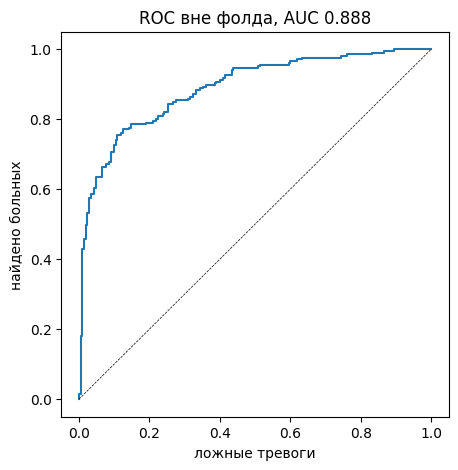

чувствительность при специфичности 90%: 73%  (ориентир FIT: ~74% при ~95%)


In [10]:
# итоговая модель: лучшая по проверке «новая страна»
best = results.sort_values('новая страна', ascending=False).iloc[0]
print('выбрано:', best['признаки'], '|', best['модель'])
F_tr, F_te = SETS[best['признаки']], {'только таксоны': T_te, 'только 8 признаков': B_te,
                                       'таксоны + 8 признаков': pd.concat([T_te, B_te], axis=1)}[best['признаки']]
final = MODELS[best['модель']]().fit(F_tr.values, y)
sub = pd.DataFrame({'sample_id': test.sample_id, 'label': final.predict_proba(F_te.values)[:, 1]})
sub.to_csv('submission.csv', index=False)
print('submission.csv:', sub.shape)

# ROC-кривая по внефолдовым предсказаниям и чувствительность при специфичности 90%
oof = np.zeros(len(y))
for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(F_tr, strata):
    oof[te] = MODELS[best['модель']]().fit(F_tr.values[tr], y[tr]).predict_proba(F_tr.values[te])[:, 1]
fpr, tpr, _ = roc_curve(y, oof)
sens90 = tpr[fpr <= 0.10].max()
plt.figure(figsize=(5, 5)); plt.plot(fpr, tpr); plt.plot([0, 1], [0, 1], 'k--', lw=.5)
plt.title(f'ROC вне фолда, AUC {roc_auc_score(y, oof):.3f}'); plt.xlabel('ложные тревоги'); plt.ylabel('найдено больных'); plt.show()
print(f'чувствительность при специфичности 90%: {sens90:.0%}  (ориентир FIT: ~74% при ~95%)')

## 7. Интерпретация

Коэффициенты L2-логистики на стандартизованных признаках: знак показывает направление, величина — силу.

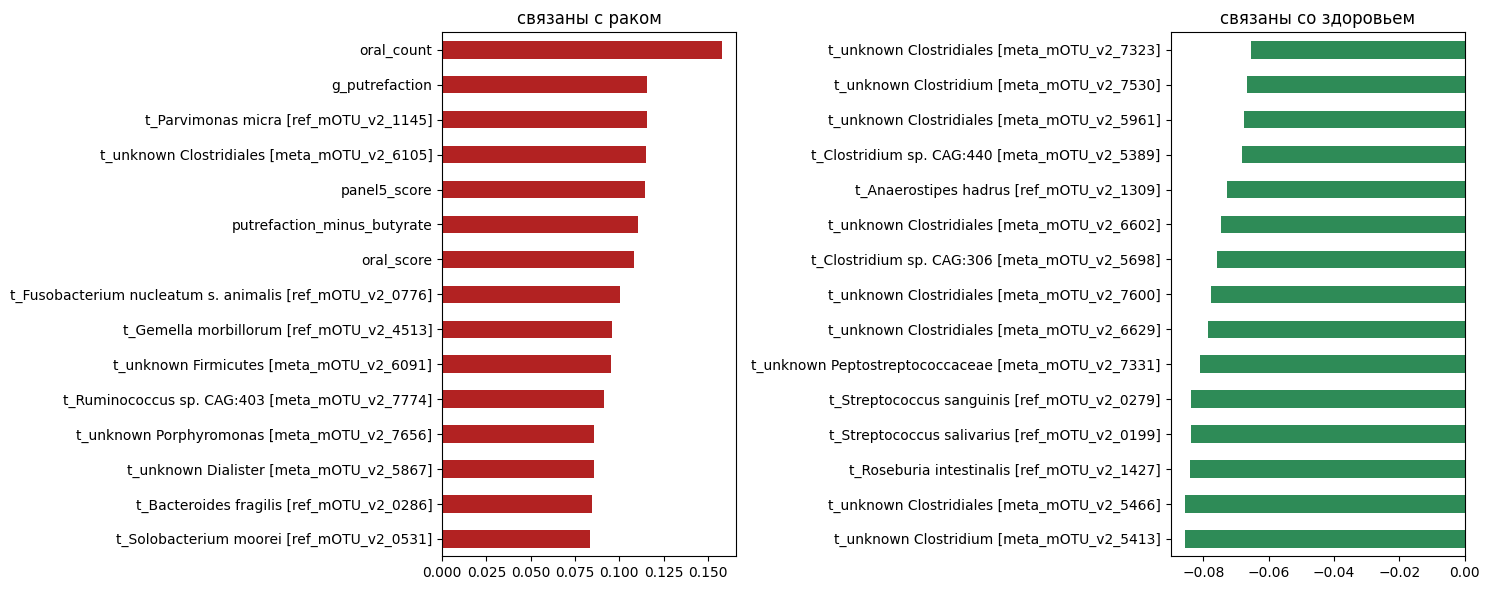

In [11]:
F_all = pd.concat([T_tr, B_tr], axis=1)
lr = MODELS['L2 logistic']().fit(F_all.values, y)
coef = pd.Series(lr[-1].coef_[0], index=F_all.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
coef.tail(15).plot.barh(ax=ax[0], color='firebrick'); ax[0].set_title('связаны с раком')
coef.head(15).plot.barh(ax=ax[1], color='seagreen'); ax[1].set_title('связаны со здоровьем')
plt.tight_layout(); plt.show()

In [12]:
# проверка устойчивости: пол
for g in ['M', 'F']:
    m = (train.gender == g).values
    print(g, 'AUC ротового счёта', round(roc_auc_score(y[m], B_tr.oral_score[m]), 3), '| AUC вне фолда', round(roc_auc_score(y[m], oof[m]), 3))
# ловушка: таксон одной страны
c = [x for x in TAXA if x.startswith('Prevotella copri')][0]
print('Prevotella copri по странам:', {k: round(roc_auc_score(y[cohort == k], np.log10(train.loc[cohort == k, c] + PSEUDO)), 2) for k in COHORTS})

M AUC ротового счёта 0.846 | AUC вне фолда 0.904
F AUC ротового счёта 0.753 | AUC вне фолда 0.862
Prevotella copri по странам: {'AUS': 0.81, 'CHI': 0.48, 'FRA': 0.49, 'GER': 0.3, 'USA': 0.41}


**Как читать результат**
* В топе стоят ротовые бактерии (Parvimonas micra, Fusobacterium nucleatum animalis, Gemella morbillorum, Peptostreptococcus stomatis, Solobacterium moorei, Dialister) и биологические признаки. Это совпадает с метаанализами Wirbel 2019, Thomas 2019, Dai 2018 и Piccinno 2025.
* На стороне здоровья стоят продуценты бутирата: Roseburia intestinalis, Faecalibacterium, Anaerostipes, Eubacterium rectale.
* Prevotella copri — пример ловушки: в Австрии она связана с раком, в Германии наоборот, а в целом сигнала нет. Это диета, а не рак.

## 8. Ограничения и выводы

* Данные поперечные: видна связь бактерий с раком, но не причинность. Часть сигнала может давать сама опухоль, создающая нишу этим бактериям.
* Стадий рака нет, поэтому неизвестно, как модель видит ранний рак, а для скрининга важен именно он.
* Вещества, которые выделяют бактерии, выведены из литературы, а не измерены. Метаболомики в данных нет.
* У женщин сигнал слабее, чем у мужчин. Самая трудная страна при проверке — США.
* Биологические признаки собраны по литературе, но после просмотра train, поэтому возможен небольшой оптимизм. На тесте разумно ждать 0,85–0,88. Самый большой метаанализ (Piccinno 2025, 3741 образец) даёт в среднем 0,85.

In [13]:
display(sub)

,sample_id,label
0,S0125,0.484899
1,S0242,0.472992
2,S0053,0.321597
3,S0173,0.199774
4,S0453,0.646295
...,...,...
155,S0491,0.749060
156,S0360,0.673247
157,S0192,0.620230
158,S0005,0.876979
